# Atividade Prática: Manipulação e Decisões de Visualização de Dados das IFES

**Dupla:** Nathan Mateus de Lima e Vítor Oliveira Amorim  
**Professora:** Carolina Ribeiro Xavier  
**Disciplina:** Tecnologias para Data Science  

### 1.  Carregar, Preparar e Explorar os Dados

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

sns.set_theme(style='whitegrid')

In [2]:
df = pd.read_csv("dados_investimento_e_vagas_ifes.csv")
df.head()

,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
0,1996,32.1,0.02,342100,26800,43100,8200
1,1997,31.8,0.02,351400,27100,42800,8600
2,1998,30.5,0.03,362900,27400,42100,9100
3,1999,29.8,0.03,375200,27600,41500,9800
4,2000,31.2,0.04,391800,28100,41900,10400


In [3]:
print(df.describe())

               ano  investimento_total_ifes_bilhoes_brl  \
count    31.000000                            31.000000   
mean   2011.000000                            53.019355   
std       9.092121                            15.830802   
min    1996.000000                            29.800000   
25%    2003.500000                            34.350000   
50%    2011.000000                            54.100000   
75%    2018.500000                            65.950000   
max    2026.000000                            76.500000   

       investimento_assistencia_estudantil_bilhoes_brl  num_vagas_estudantes  \
count                                        31.000000          3.100000e+01   
mean                                          0.693548          8.967581e+05   
std                                           0.534749          4.008678e+05   
min                                           0.020000          3.421000e+05   
25%                                           0.070000          4.65

### Evolução Temporal e Ajuste de Escalas

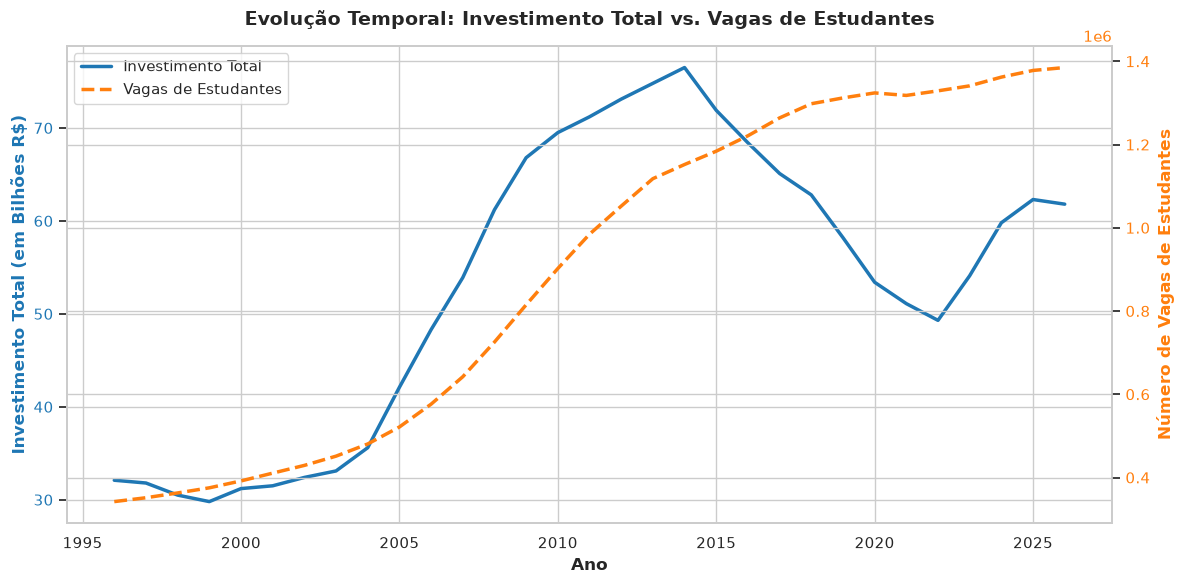

In [4]:
df_agrupado = (
    df.groupby('ano')
    .agg(
        {
            'investimento_total_ifes_bilhoes_brl': 'sum',
            'num_vagas_estudantes': 'sum',
        }
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Ano', fontsize=12, fontweight='bold')
ax1.set_ylabel(
    'Investimento Total (em Bilhões R$)',
    color=color,
    fontsize=12,
    fontweight='bold',
)
line1 = ax1.plot(
    df_agrupado['ano'],
    df_agrupado['investimento_total_ifes_bilhoes_brl'],
    color=color,
    linewidth=2.5,
    label='Investimento Total',
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel(
    'Número de Vagas de Estudantes',
    color=color,
    fontsize=12,
    fontweight='bold',
)
line2 = ax2.plot(
    df_agrupado['ano'],
    df_agrupado['num_vagas_estudantes'],
    color=color,
    linewidth=2.5,
    linestyle='--',
    label='Vagas de Estudantes',
)
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.title(
    'Evolução Temporal: Investimento Total vs. Vagas de Estudantes',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
fig.tight_layout()
plt.show()

Analisando o gráfico de linha com eixo duplo, percebe-se que o Investimento Total e Número de Vagas de Estudantes cresce de forma conjunta até por volta de 2004, a partir desse ano, até por volta de 2014 o Investimento Total cresceu de forma maior quando comparado com o Número de Vagas, apesar que este também cresceu consideravelmente. De 2014 a 2022, o Investimento Total teve um grande efeito de queda, voltando a crescer após 2022, entretanto essa queda no Investimento Total não foi refletida no Número de Vagas de Estudantes, o qual apesar de apresentar um crescimento mais acentuado do que seus anos anteriores, continuou crescendo mesmo com menos investimentos.

Foi utilizado o gráfico de linha com eixo duplo, devido a discrepância nas ordens de grandeza das variáveis "Investimento Total" e "Número de Vagas". O eixo duplo permite que os dois valores sejam analisados, sem que os valores de Número de Vagas de Estudantes não sejam "achatados" na representação, quando comparado com Investimento Total cujos os valores estão na casa dos bilhões.

### Análise de Proporção de Força de Trabalho (Docentes vs. TAEs)

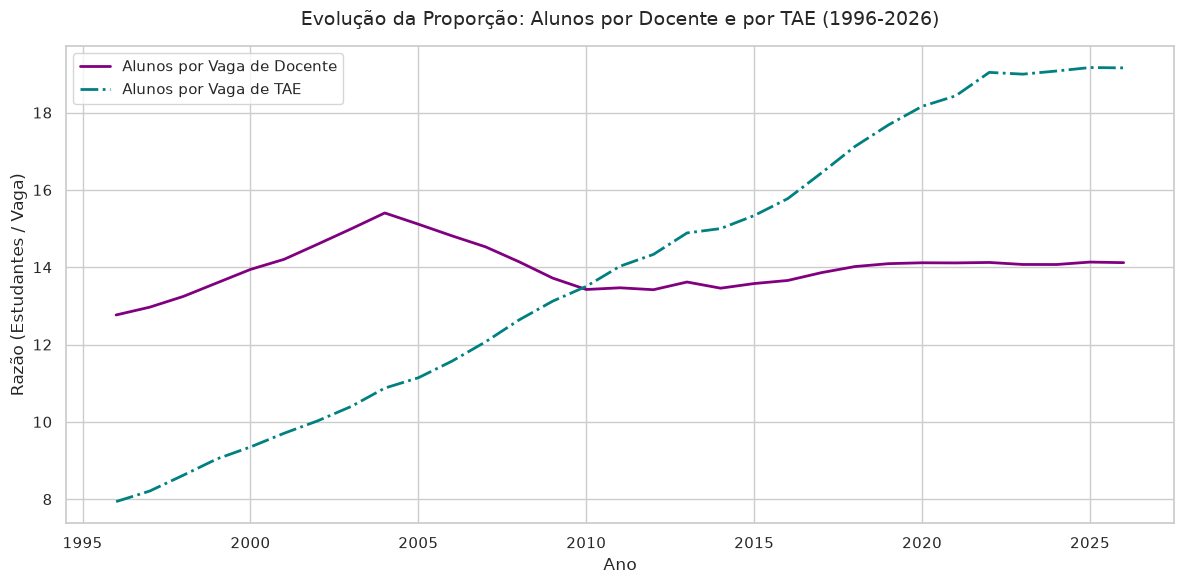

In [6]:
df['prop_estudante_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['prop_estudante_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

plt.figure(figsize=(12, 6))
plt.plot(
    df['ano'],
    df['prop_estudante_docente'],
    label='Alunos por Vaga de Docente',
    linewidth=2,
    color='purple',
)
plt.plot(
    df['ano'],
    df['prop_estudante_tae'],
    label='Alunos por Vaga de TAE',
    linewidth=2,
    color='teal',
    linestyle='-.',
)

plt.title(
    'Evolução da Proporção: Alunos por Docente e por TAE (1996-2026)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Razão (Estudantes / Vaga)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

O gráfico de linhas múltiplas demonstra que enquanto a quantidade de alunos (número de vagas estudantes) por vaga Docente apresentou um comportamento mais estável, enquanto a linha de alunos por vaga TAE apresentou um crescimento contínuo, demonstrando um possível déficit de mão de obra técnico administrativa, quando comparada com os anos iniciais dos dados.

A escolha desse gráfico se deve as escalas de valores serem muito semelhantes, com esse gráfico de múltiplas linhas permitindo uma comparação mais direta entre os dois e permitindo ver sua atualização no passar dos anos.

### Correlação entre Fatores e Desempenho Orçamentário (Método agg):

In [7]:
def categorizar_periodo(ano):
  if ano <= 2002:
    return '1996-2002'
  elif 2003 <= ano <= 2010:
    return '2003-2010'
  elif 2011 <= ano <= 2016:
    return '2011-2016'
  elif 2017 <= ano <= 2022:
    return '2017-2022'
  else:
    return '2023+'

df['periodo'] = df['ano'].apply(categorizar_periodo)

          investimento_assistencia_estudantil_bilhoes_brl               \
                                                     mean median   sum   
periodo                                                                  
1996-2002                                        0.032857  0.030  0.23   
2003-2010                                        0.312500  0.215  2.50   
2011-2016                                        1.190000  1.245  7.14   
2017-2022                                        1.145000  1.165  6.87   
2023+                                            1.190000  1.215  4.76   

          num_vagas_estudantes                      
                          mean     median      sum  
periodo                                             
1996-2002         3.804286e+05   375200.0  2663000  
2003-2010         6.392500e+05   609150.0  5114000  
2011-2016         1.118583e+06  1135000.0  6711500  
2017-2022         1.307500e+06  1315000.0  7845000  
2023+             1.366500e+06  1370

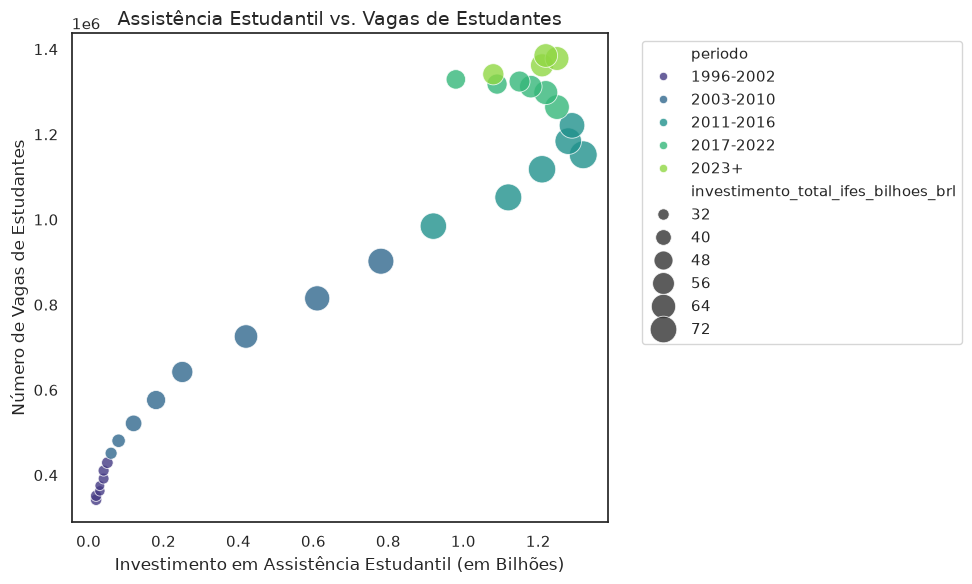

In [9]:
resumo_agg = df.groupby('periodo').agg({
    'investimento_assistencia_estudantil_bilhoes_brl': ['mean', 'median', 'sum'],
    'num_vagas_estudantes': ['mean', 'median', 'sum'],
})
print(resumo_agg)

# Bubble Chart com Seaborn
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='investimento_assistencia_estudantil_bilhoes_brl',
    y='num_vagas_estudantes',
    size='investimento_total_ifes_bilhoes_brl',
    hue='periodo',
    palette='viridis',
    sizes=(50, 400),
    alpha=0.8,
)
plt.title(
    'Assistência Estudantil vs. Vagas de Estudantes',
    fontsize=14,
)
plt.xlabel(
    'Investimento em Assistência Estudantil (em Bilhões)', fontsize=12
)
plt.ylabel('Número de Vagas de Estudantes', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Analisando o gráfico de dispersão com tamanho de ponto proporcional, podemos notar que o período de 1996-2002 teve os menores valores tanto em investimento total, como em número de vagas de estudante se investimento em assistência estudantil. Os períodos 2003-2010 e 2011-2016, apresentaram um crescimento considerável nos 3 ambitos. Por fim, os períodos de 2017-2022 e 2023+, apesar de apresentarem maiores número de vagas de estudantes e investimento em assistência estudantil, teve-se que o investimento total em bilhos diminuiu consideravelmente quando comparado com os outros períodos.

Foi escolhido esse gráfico devido a sua capacidade de compartilhar as  três informações ao mesmo tempo, permitindo uma análise associativa sem a necessidade de analisar vários gráficos, entre: Número de Vagas de Estudantes, Investimento em Assistência Estudantil, e Investimento Total.

### Filtragem Condicional de Anos Críticos (filter)

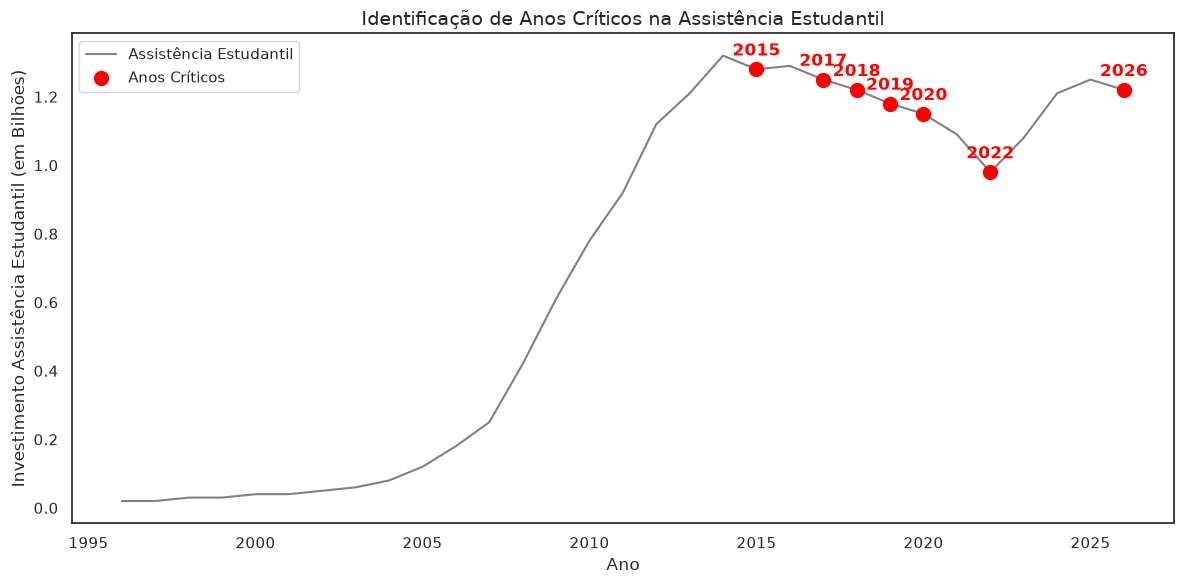

In [10]:
df['dif_assistencia'] = df['investimento_assistencia_estudantil_bilhoes_brl'].diff()
df['dif_vagas'] = df['num_vagas_estudantes'].diff()

anos_criticos = df[
    (df['dif_assistencia'] < 0) & (df['dif_vagas'] > 0)
]['ano'].tolist()

plt.figure(figsize=(12, 6))
plt.plot(
    df['ano'],
    df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='gray',
    linewidth=1.5,
    label='Assistência Estudantil',
)

criticos_df = df[df['ano'].isin(anos_criticos)]
plt.scatter(
    criticos_df['ano'],
    criticos_df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='red',
    s=100,
    zorder=5,
    label='Anos Críticos',
)

for ano in anos_criticos:
  y_val = df.loc[df['ano'] == ano, 'investimento_assistencia_estudantil_bilhoes_brl'].values[
      0
  ]
  plt.annotate(
      f'{ano}',
      (ano, y_val),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontweight='bold',
      color='red',
  )

plt.title('Identificação de Anos Críticos na Assistência Estudantil', fontsize=14)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Investimento Assistência Estudantil (em Bilhões)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Nota-se que do ano 1996 a 2014 houve um crescimento exponencial no Investimento Assistência Estudantil, com quase todos os anos subsequentes possuindo uma queda até o ano de 2022, onde a partir de 2023 esse investimento cresceu novamente, com exceção do ano de 2026, onde o investimento caiu novamente.

Foi escolhido o gráfico de linhas com marcações em cor vermelha nos anos onde houve uma queda no investimento assistência estudantil ao mesmo tempo que o número de vagas cresceu, essa escolha se deve ao gráfico de linhas ser ótimo para analisar séries temporais, nesse caso o Investimento Assistência Estudantil, com as marcações em vermelho permitindo visualizar facilmente os anos em que houve esse comportamento entre o investimento e número de vagas.